In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
data=pd.read_csv("E0 without odds.csv")

In [3]:
data.head()

,Div,Date,Time,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,...,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR
0,E0,5/8/2022,20:00,Crystal Palace,Arsenal,0,2,A,0,1,...,2,2,16,11,3,5,1,2,0,0
1,E0,6/8/2022,12:30,Fulham,Liverpool,2,2,D,1,0,...,3,4,7,9,4,4,2,0,0,0
2,E0,6/8/2022,15:00,Bournemouth,Aston Villa,2,0,H,1,0,...,3,2,18,16,5,5,3,3,0,0
3,E0,6/8/2022,15:00,Leeds,Wolves,2,1,H,1,1,...,4,6,13,9,6,4,2,0,0,0
4,E0,6/8/2022,15:00,Newcastle,Nott'm Forest,2,0,H,0,0,...,10,0,9,14,11,1,0,3,0,0


In [4]:
data.nunique()

Div           1
Date        117
Time         15
HomeTeam     20
AwayTeam     20
FTHG          9
FTAG          7
FTR           3
HTHG          6
HTAG          4
HTR           3
Referee      23
HS           30
AS           26
HST          14
AST          12
HF           19
AF           21
HC           17
AC           17
HY            7
AY            8
HR            3
AR            2
dtype: int64

In [5]:
Home_teams = data['HomeTeam']
Home_teams.duplicated().sum()

360

In [6]:
Away_teams = data['AwayTeam']

In [7]:
Home_teams_total = Home_teams.drop_duplicates()

In [8]:
Away_teams_total = Home_teams_total
Away_teams_total

0     Crystal Palace
1             Fulham
2        Bournemouth
3              Leeds
4          Newcastle
5          Tottenham
6            Everton
7          Leicester
8         Man United
9           West Ham
10       Aston Villa
11           Arsenal
12          Brighton
13          Man City
14       Southampton
15            Wolves
16         Brentford
17     Nott'm Forest
18           Chelsea
19         Liverpool
Name: HomeTeam, dtype: object

In [9]:
Home_team_goals = data['FTHG']
Away_team_goals = data['FTAG']

In [10]:
result_data = pd.DataFrame({
    "HomeTeam": Home_teams,
    "AwayTeam": Away_teams,
    "FTHG": Home_team_goals,
    "FTAG": Away_team_goals
})

In [11]:
result_data.head()

,HomeTeam,AwayTeam,FTHG,FTAG
0,Crystal Palace,Arsenal,0,2
1,Fulham,Liverpool,2,2
2,Bournemouth,Aston Villa,2,0
3,Leeds,Wolves,2,1
4,Newcastle,Nott'm Forest,2,0


In [12]:
home_team_goals = result_data.groupby("HomeTeam")['FTHG'].sum()
home_team_goals

HomeTeam
Arsenal           53
Aston Villa       33
Bournemouth       20
Brentford         35
Brighton          37
Chelsea           20
Crystal Palace    21
Everton           16
Fulham            31
Leeds             26
Leicester         23
Liverpool         46
Man City          60
Man United        36
Newcastle         36
Nott'm Forest     27
Southampton       19
Tottenham         37
West Ham          26
Wolves            19
Name: FTHG, dtype: int64

In [13]:
away_team_goals = result_data.groupby("AwayTeam")['FTAG'].sum()
away_team_goals

AwayTeam
Arsenal           35
Aston Villa       18
Bournemouth       17
Brentford         23
Brighton          35
Chelsea           18
Crystal Palace    19
Everton           18
Fulham            24
Leeds             22
Leicester         28
Liverpool         29
Man City          34
Man United        22
Newcastle         32
Nott'm Forest     11
Southampton       17
Tottenham         33
West Ham          16
Wolves            12
Name: FTAG, dtype: int64

In [14]:
teams = []
teams = Home_teams_total

teams.sort_values(inplace=True)
teams

11           Arsenal
10       Aston Villa
2        Bournemouth
16         Brentford
12          Brighton
18           Chelsea
0     Crystal Palace
6            Everton
1             Fulham
3              Leeds
7          Leicester
19         Liverpool
13          Man City
8         Man United
4          Newcastle
17     Nott'm Forest
14       Southampton
5          Tottenham
9           West Ham
15            Wolves
Name: HomeTeam, dtype: object

In [15]:
x = np.arange(len(teams))
x

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19])

In [16]:
bar_width = 0.25

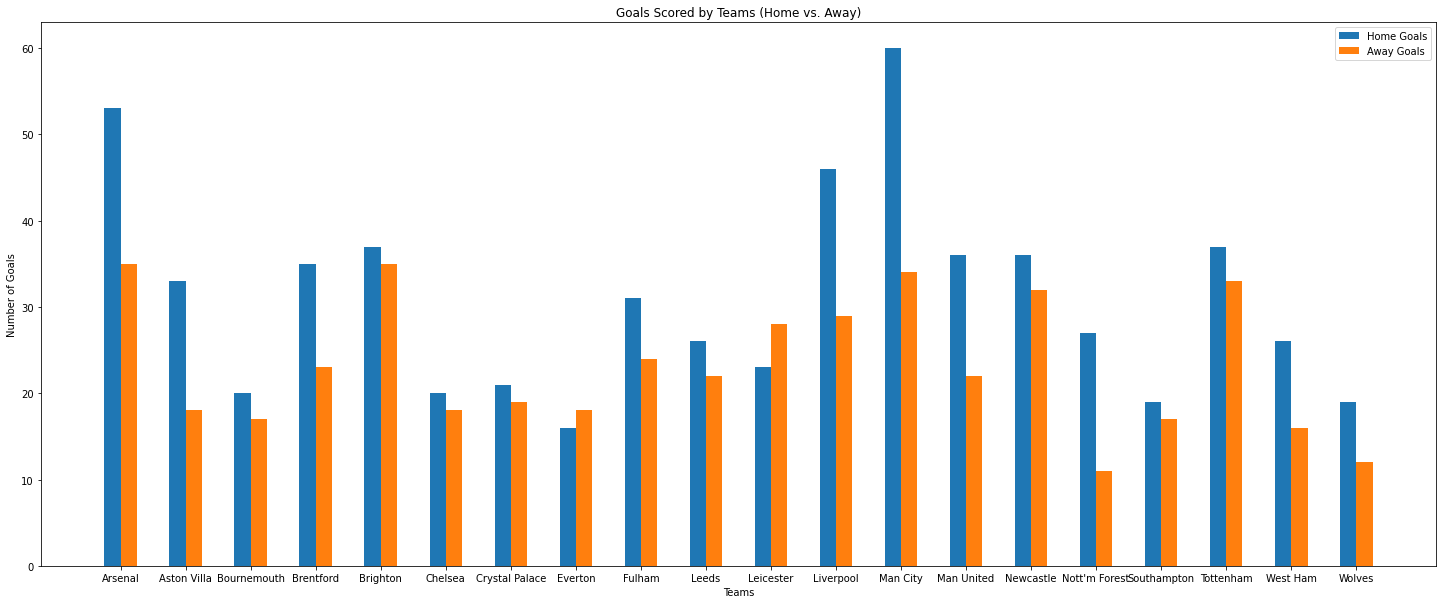

In [17]:
plt.figure(figsize=(25,10))
plt.bar(x - bar_width/2, home_team_goals, width=bar_width, label='Home Goals')
plt.bar(x + bar_width/2, away_team_goals, width=bar_width, label='Away Goals')
plt.xlabel('Teams')
plt.ylabel('Number of Goals')
plt.title('Goals Scored by Teams (Home vs. Away)')
plt.xticks(x, teams)
plt.legend()